In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [27]:
from sklearn.datasets import load_breast_cancer
X,y = load_breast_cancer(return_X_y=True, as_frame=True)


In [ ]:


X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.4, random_state=1, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_hold, y_hold, test_size=0.5, random_state=1, stratify=y_hold)

print(y_train.shape)
print(y_valid.shape)
print(y_test.shape)


(341,)
(114,)
(114,)


In [51]:
logreg_mod = model_2 = LogisticRegression(solver='lbfgs', penalty=None, max_iter=5000)
logreg_mod.fit(X_train, y_train)
log_y_pred = logreg_mod.predict(X_test)


print('Training Accuracy:  ', round(logreg_mod.score(X_train, y_train),4))
print('Validation Accuracy:', round(logreg_mod.score(X_test, y_test),4))


logcm = confusion_matrix(y_test, log_y_pred)
print(logcm)
print(pd.DataFrame(logcm, index=['Actual M', 'Actual B', ],
            columns=['Pred M', 'Pred B', ], ))
classM_precision = np.sum((log_y_pred == 0) & (y_test == 0) ) / np.sum(log_y_pred == 0)
classM_recall = np.sum((log_y_pred == 0) & (y_test == 0) ) / np.sum(y_test == 0)

print('Malignant Precision:', round(classM_precision,4))
print('Malignant Recall:   ', round(classM_recall,4))
classB_precision = np.sum((log_y_pred == 1) & (y_test == 1) ) / np.sum(log_y_pred == 1)
classB_recall = np.sum((log_y_pred == 1) & (y_test == 1) ) / np.sum(y_test == 1)

print('Benign Precision:', round(classB_precision,4))
print('Benign Recall:   ', round(classB_recall,4))

Training Accuracy:   0.9912
Validation Accuracy: 0.9825
[[41  1]
 [ 1 71]]
          Pred M  Pred B
Actual M      41       1
Actual B       1      71
Malignant Precision: 0.9762
Malignant Recall:    0.9762
Benign Precision: 0.9861
Benign Recall:    0.9861


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


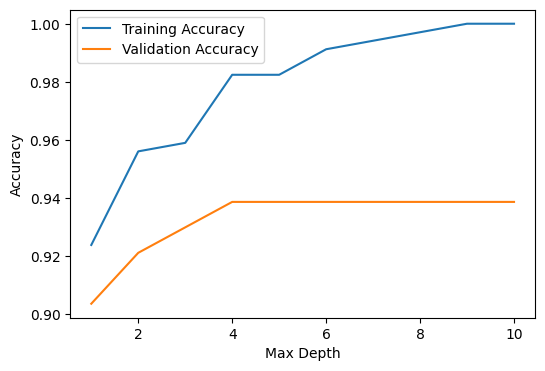

In [ ]:
tr_acc = []
va_acc = []

depth_list = range(1,11)

for d in depth_list:
    temp_mod = DecisionTreeClassifier(max_depth=d, random_state=1)
    temp_mod.fit(X_train, y_train)
    tr_acc.append(temp_mod.score(X_train, y_train))
    va_acc.append(temp_mod.score(X_valid, y_valid))

plt.figure(figsize=([6,4]))
plt.plot(depth_list, tr_acc, label='Training Accuracy')
plt.plot(depth_list, va_acc, label='Validation Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
ix_best = np.argmax(va_acc)
best_md = depth_list[ix_best]
print('Optimal Value of max_depth:', best_md)

Optimal Value of max_depth: 4


In [48]:
tree_mod = DecisionTreeClassifier(max_depth=best_md, random_state=1)
tree_mod.fit(X_train, y_train)

print('Training Accuracy:  ', round(tree_mod.score(X_train, y_train),4))
print('Validation Accuracy:', round(tree_mod.score(X_valid, y_valid),4))
classA_precision = np.sum((y_hold == 0) & (y_valid == 0) ) / np.sum(y_hold == 0)
classA_recall = np.sum((y_hold == 0) & (y_valid == 0) ) / np.sum(y_valid == 0)

print('Class A Precision:', round(classA_precision,4))
print('Class A Recall:   ', round(classA_recall,4))
tree_y_pred = tree_mod.predict(X_test)
treecm = confusion_matrix(y_test, tree_y_pred)
print(treecm)
pd.DataFrame(cm, index=['Actual M', 'Actual B', ],
            columns=['Pred M', 'Pred B', ], )
classM_precision = np.sum((tree_y_pred == 0) & (y_test == 0) ) / np.sum(tree_y_pred == 0)
classM_recall = np.sum((tree_y_pred == 0) & (y_test == 0) ) / np.sum(y_test == 0)

print('Malignant Precision:', round(classM_precision,4))
print('Malignant Recall:   ', round(classM_recall,4))

classB_precision = np.sum((tree_y_pred == 1) & (y_test == 1) ) / np.sum(tree_y_pred == 1)
classB_recall = np.sum((tree_y_pred == 1) & (y_test == 1) ) / np.sum(y_test == 1)

print('Benign Precision:', round(classB_precision,4))
print('Benign Recall:   ', round(classB_recall,4))


Training Accuracy:   0.9824
Validation Accuracy: 0.9386
Class A Precision: 0.5059
Class A Recall:    1.0
[[38  4]
 [ 0 72]]
Malignant Precision: 1.0
Malignant Recall:    0.9048
Benign Precision: 0.9474
Benign Recall:    1.0


Training Accuracy:   0.9853
Validation Accuracy: 0.9298


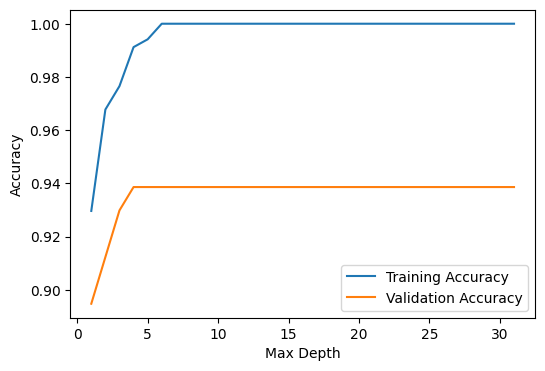

Optimal Value of max_depth: 4
[[38  4]
 [ 0 72]]
Malignant Precision: 1.0
Malignant Recall:    0.9524
Benign Precision: 0.973
Benign Recall:    1.0


In [49]:
forest_mod = RandomForestClassifier(n_estimators=500, max_depth=4, random_state=1)
forest_mod.fit(X_train, y_train)

print('Training Accuracy:  ', round(forest_mod.score(X_train, y_train),4))
print('Validation Accuracy:', round(forest_mod.score(X_valid, y_valid),4))
ix_best = np.argmax(va_acc)
best_md = depth_list[ix_best]
depth_list = range(1,32)
tr_acc = []
va_acc = []
for d in depth_list:
    temp_mod = RandomForestClassifier(max_depth=d, random_state=1)
    temp_mod.fit(X_train, y_train)
    tr_acc.append(temp_mod.score(X_train, y_train))
    va_acc.append(temp_mod.score(X_valid, y_valid))
plt.figure(figsize=([6,4]))
plt.plot(depth_list, tr_acc, label='Training Accuracy')
plt.plot(depth_list, va_acc, label='Validation Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
ix_best = np.argmax(va_acc)
best_md = depth_list[ix_best]
print('Optimal Value of max_depth:', best_md)

forest_y_pred = forest_mod.predict(X_test)
forestcm = confusion_matrix(y_test, tree_y_pred)
print(forestcm)
pd.DataFrame(cm, index=['Actual M', 'Actual B', ],
            columns=['Pred M', 'Pred B', ], )
classM_precision = np.sum((forest_y_pred == 0) & (y_test == 0) ) / np.sum(forest_y_pred == 0)
classM_recall = np.sum((forest_y_pred == 0) & (y_test == 0) ) / np.sum(y_test == 0)

print('Malignant Precision:', round(classM_precision,4))
print('Malignant Recall:   ', round(classM_recall,4))

classB_precision = np.sum((forest_y_pred == 1) & (y_test == 1) ) / np.sum(forest_y_pred == 1)
classB_recall = np.sum((forest_y_pred == 1) & (y_test == 1) ) / np.sum(y_test == 1)

print('Benign Precision:', round(classB_precision,4))
print('Benign Recall:   ', round(classB_recall,4))

In [ ]:
print('Test Set Accuracy:', round(logreg_mod.score(X_test, y_test),4))

Test Set Accuracy: 0.9825


The logreg model had the highest malignant recall, meaning it was the least likely to miss a malignant and label it benign.

Task 4.
a) The probability it 41/42 that they have cancer. 42 total were predicted malignant but one was actually benign.
b)The probability of a benign result meaning you don't have cancer would be 71/72. The model predicted 72 benign tumors and 71 of them were actually benign.

Task 5.
Minimizing missing a disease is good because false negatives seriously want to be avoided, especially with something deadly like cancer. You want anybody that could potentially have cancer to go through further checks. The issue is that the more sensitive your test is, the more false positives you get. While a false positive is better than a false negative they do become a waste of time, money and resources if they recieve further testing and discover they never had cancer to begin with. It also causes extra stress, but accidentally picking up people who are actually fine is better than missing those who do have the disease.